# Diagnóstico de Tumores Cerebrais com Aprendizagem Automática

**Unidade Curricular:** Aprendizagem Automática  
**Ano Letivo:** 2025/2026  
**Tema:** Diagnóstico de tumores cerebrais a partir de dados demográficos e características de textura (ADC / GLCM).

Este notebook funciona como **relatório completo** do trabalho prático.  
Aqui serão descritos:

1. Caracterização e análise do conjunto de dados
2. Pré-processamento e seleção/transformação de atributos
3. Experiências com diferentes modelos de aprendizagem automática
4. Avaliação e escolha dos melhores modelos
5. Preparação dos ficheiros de submissão para o Kaggle
6. Discussão de resultados e conclusões


## 1. Importação de bibliotecas

**Objetivo**: Importar todas as bibliotecas necessárias para análise de dados, visualização, pré-processamento e modelagem de machine learning.

**Justificativa**: Escolhemos bibliotecas padronizadas da comunidade Python para data science:

*   pandas e numpy para manipulação de dados
*   matplotlib e seaborn para visualização
*   scikit-learn para todo o pipeline de machine learning
*   Três algoritmos de classificação para comparação

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
try:
    import seaborn as sns
    _HAS_SEABORN = True
except ModuleNotFoundError:
    sns = None
    _HAS_SEABORN = False
    print('Aviso: seaborn não está instalado.')

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

RANDOM_STATE = 42
if _HAS_SEABORN:
    sns.set(style="whitegrid")

Aviso: seaborn não está instalado.


## 2. Carregamento dos dados


**Objetivo**: Carregar os conjuntos de treino e teste a partir dos ficheiros CSV.

**Justificativa**:

*   Os dados estão organizados em dois ficheiros separados: treino.csv e teste.csv .
*   É fundamental verificar as dimensões dos conjuntos para garantir que foram carregados corretamente.  
*   A visualização inicial das primeiras linhas ajuda a entender a estrutura dos dados.   

**Resultado**:

*   Conjunto de treino: 1393 amostras × 19 características.
*   Conjunto de teste: 400 amostras × 18 características (sem o diagnóstico).

In [2]:
# Ajustar o caminho se necessário
train_path = "treino.csv"
test_path = "teste.csv"

treino = pd.read_csv(train_path)
teste = pd.read_csv(test_path)

print("Dimensões do treino:", treino.shape)
print("Dimensões do teste:", teste.shape)

treino.head()

Dimensões do treino: (1393, 19)
Dimensões do teste: (400, 18)


,id,idade,sexo,id_fatia,med_ADC,assimetria,curtose,med1_GLCM,med2_GLCM,var1_GLCM,var2_GLCM,energia_GLCM,entropia_GLCM,contraste_GLCM,homogeneidade_GLCM,correlação_GLCM,proiminência_GLCM,sombra_GLCM,diagnostico
0,1,78,m,5.1,1208.988,11.092,2.774,9.817,9.860,14.637,16.047,0.052,3.507,14.646,0.462,0.523,1.427,1.855,1
1,1,78,m,5.2,897.146,3.044,0.169,7.171,7.482,1.068,2.981,0.081,2.887,3.262,0.571,0.248,1.576,2.076,1
2,1,78,m,5.3,895.563,7.827,2.068,7.133,7.457,2.850,6.443,0.076,3.135,5.941,0.550,0.403,1.809,2.405,1
3,1,78,m,5.4.1,1080.107,3.091,0.832,8.725,9.437,3.680,12.681,0.041,3.728,9.834,0.504,0.515,1.948,2.573,1
4,1,78,m,5.4.2,1025.789,14.450,3.005,8.282,8.736,4.202,12.335,0.067,3.204,9.046,0.548,0.535,2.158,2.920,1


# 3. Análise Exploratória dos Dados (EDA)
**Objetivo**: Realizar uma análise exploratória completa dos dados para entender sua estrutura, qualidade e distribuição.

**Justificativa**:

*   Verificação de tipos de dados para garantir compatibilidade com algoritmos.   
*   Identificação de valores em falta que poderiam prejudicar o modelo.
*   Análise da distribuição da variável alvo para detectar desbalanceamento  .  
*   Estatísticas descritivas para entender a escala e distribuição das features .   

**Resultados**:

1.  **Tipos de dados**: Mistura de numéricos (int64, float64) e categóricos (object)   . 
2.  **Valores em falta**: Nenhum valor em falta em nenhuma coluna .   
3.  **Distribuição do diagnóstico**: 54.4% positivos (tumor), 45.6% negativos (razoavelmente balanceado) .  
4.  **Estatísticas descritivas**: Variações significativas nas features GLCM.

In [3]:
# Informações
print("Tipos de dados (treino):")
print(treino.dtypes)
print("\nValores em falta (treino):")
print(treino.isna().sum())

print("\nDistribuição da variável alvo (diagnostico):")
print(treino["diagnostico"].value_counts(normalize=True))

treino.describe(include="all")

Tipos de dados (treino):
id                      int64
idade                   int64
sexo                   object
id_fatia               object
med_ADC               float64
assimetria            float64
curtose               float64
med1_GLCM             float64
med2_GLCM             float64
var1_GLCM             float64
var2_GLCM             float64
energia_GLCM          float64
entropia_GLCM         float64
contraste_GLCM        float64
homogeneidade_GLCM    float64
correlação_GLCM       float64
proiminência_GLCM     float64
sombra_GLCM           float64
diagnostico             int64
dtype: object

Valores em falta (treino):
id                    0
idade                 0
sexo                  0
id_fatia              0
med_ADC               0
assimetria            0
curtose               0
med1_GLCM             0
med2_GLCM             0
var1_GLCM             0
var2_GLCM             0
energia_GLCM          0
entropia_GLCM         0
contraste_GLCM        0
homogeneidade_GLCM    0
cor

,id,idade,sexo,id_fatia,med_ADC,assimetria,curtose,med1_GLCM,med2_GLCM,var1_GLCM,var2_GLCM,energia_GLCM,entropia_GLCM,contraste_GLCM,homogeneidade_GLCM,correlação_GLCM,proiminência_GLCM,sombra_GLCM,diagnostico
count,1393.000000,1393.000000,1393,1393,1393.000000,1393.000000,1393.000000,1393.000000,1393.000000,1393.000000,1393.000000,1393.000000,1393.000000,1393.000000,1393.000000,1393.000000,1393.000000,1393.000000,1393.000000
unique,NaN,NaN,2,1388,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,f,214.1.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,765,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,92.819813,46.450826,NaN,NaN,1108.658307,5.134572,0.726991,8.969625,9.183479,4.376971,6.594537,0.081952,3.205197,5.169363,0.546917,0.504739,0.887137,1.252377,0.544149
std,51.203124,18.770829,NaN,NaN,412.748470,4.135578,1.052737,3.519968,3.397307,5.281116,7.473869,0.072727,0.770853,5.725974,0.128801,0.175807,0.968834,1.366289,0.498226
min,1.000000,1.000000,NaN,NaN,282.689000,1.550000,-4.750000,2.087000,2.483000,0.134000,0.150000,0.008000,0.942000,0.240000,0.185000,-0.083000,-2.650000,-3.297000,0.000000
25%,52.000000,36.000000,NaN,NaN,860.840000,2.960000,0.100000,6.852000,7.031000,1.160000,2.012000,0.034000,2.672000,1.750000,0.458000,0.400000,0.703000,1.328000,0.000000
50%,92.000000,50.000000,NaN,NaN,1051.316000,3.792000,0.634000,8.473000,8.709000,2.700000,4.119000,0.056000,3.294000,3.273000,0.546000,0.529000,1.088000,1.549000,1.000000
75%,137.000000,60.000000,NaN,NaN,1265.033000,5.777000,1.348000,10.300000,10.625000,5.354000,8.219000,0.104000,3.766000,6.398000,0.638000,0.633000,1.424000,1.901000,1.000000


## Código para visualização da distribuição:

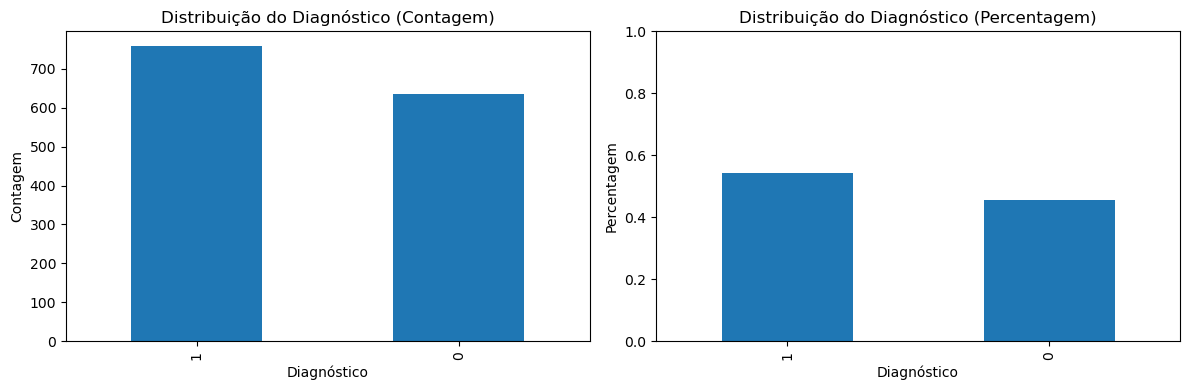

In [4]:
# Visualização da distribuição do diagnóstico
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Contagem absoluta
treino["diagnostico"].value_counts().plot(kind='bar', ax=ax[0])
ax[0].set_title('Distribuição do Diagnóstico (Contagem)')
ax[0].set_xlabel('Diagnóstico')
ax[0].set_ylabel('Contagem')

# Contagem relativa (percentagem)
treino["diagnostico"].value_counts(normalize=True).plot(kind='bar', ax=ax[1])
ax[1].set_title('Distribuição do Diagnóstico (Percentagem)')
ax[1].set_xlabel('Diagnóstico')
ax[1].set_ylabel('Percentagem')
ax[1].set_ylim([0, 1])

plt.tight_layout()
plt.show()

## 4. Pré-processamento de Dados
**Objetivo**: Preparar os dados para os algoritmos de machine learning através de transformações apropriadas.

**Justificativa**:

1.  **Remoção de identificadores**: id e id\_fatia não contêm informação preditiva úti    
2.  **Separação de features e target**: Necessário para treinar modelos supervisionados    
3.  **Codificação de variáveis categóricas**: sexo precisa ser convertida para formato numérico    
4.  **Normalização**: Importante para modelos sensíveis à escala (como Logistic Regression)    
5.  **Pipeline**: Garante consistência no pré-processamento entre treino e teste

In [5]:
# Remover colunas de identificação que não são features preditivas
features_remover = ['id', 'id_fatia']
X = treino.drop(columns=features_remover + ['diagnostico'])
y = treino['diagnostico']

X_teste_submissao = teste.drop(columns=features_remover)

# Identificar colunas categóricas e numéricas
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Colunas categóricas:", categorical_cols)
print("Colunas numéricas:", len(numerical_cols), "colunas")
print("Total de features após remoção:", X.shape[1])

Colunas categóricas: ['sexo']
Colunas numéricas: 15 colunas
Total de features após remoção: 16


### Código para criar o pipeline de pré-processamento:

In [6]:
# Criar transformers para pré-processamento
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combinar transformers usando ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

print("Pipeline de pré-processamento criado com sucesso!")

Pipeline de pré-processamento criado com sucesso!


## 5. Divisão treino/validação
**Objetivo**: Criar conjuntos de treino e validação para avaliar os modelos antes do teste final.

**Justificativa**:

*   80/20 split é uma proporção padrão que balanceia quantidade de dados para treino e validação.    
*   stratify=y garante que a proporção das classes seja mantida em ambos os conjuntos.    
*   random\_state=42 garante reprodutibilidade dos resultados.

In [7]:
# Dividir dados em treino e validação (80/20)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=RANDOM_STATE, 
    stratify=y
)

print(f"Tamanho do conjunto de treino: {X_train.shape}")
print(f"Tamanho do conjunto de validação: {X_val.shape}")
print(f"\nDistribuição no treino: {y_train.value_counts(normalize=True).values}")
print(f"Distribuição na validação: {y_val.value_counts(normalize=True).values}")

Tamanho do conjunto de treino: (1114, 16)
Tamanho do conjunto de validação: (279, 16)

Distribuição no treino: [0.54398564 0.45601436]
Distribuição na validação: [0.54480287 0.45519713]


## 6. Modelagem: Logistic Regression

**Objetivo**: Implementar e otimizar um modelo de Regressão Logística como baseline.

**Justificativa**:

*   Logistic Regression é um bom baseline por ser simples, rápido e interpretável    
*   Penalidade L2 (Ridge) ajuda a prevenir overfitting    
*   GridSearchCV encontra automaticamente os melhores hiperparâmetros    
*   Validação cruzada estratificada garante avaliação robusta

In [ ]:
# Criar pipeline completo com pré-processamento e modelo
logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))
])

# Definir parâmetros para GridSearch
logreg_params = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__penalty': ['l2'],
    'classifier__solver': ['liblinear']
}

# GridSearch com validação cruzada
logreg_grid = GridSearchCV(
    logreg_pipeline,
    logreg_params,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Treinar modelo
logreg_grid.fit(X_train, y_train)

print(f"\nMelhores parâmetros: {logreg_grid.best_params_}")
print(f"Melhor score na validação cruzada: {logreg_grid.best_score_:.3f}")

### Código para avaliação do modelo:

In [10]:
# Avaliar no conjunto de validação
y_val_pred = logreg_grid.predict(X_val)
y_val_pred_proba = logreg_grid.predict_proba(X_val)[:, 1]

# Métricas
logreg_accuracy = accuracy_score(y_val, y_val_pred)
logreg_auc = roc_auc_score(y_val, y_val_pred_proba)

print("=== Logistic Regression ===")
print(f"Acurácia na validação: {logreg_accuracy:.3f}")
print(f"AUC-ROC na validação: {logreg_auc:.3f}")
print("\nRelatório de classificação:")
print(classification_report(y_val, y_val_pred))

=== Logistic Regression ===
Acurácia na validação: 0.767
AUC-ROC na validação: 0.828

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.80      0.65      0.72       127
           1       0.75      0.86      0.80       152

    accuracy                           0.77       279
   macro avg       0.77      0.76      0.76       279
weighted avg       0.77      0.77      0.76       279



# Modelagem: Random Forest Classifier
**Objetivo**: Implementar e otimizar um modelo Random Forest, que geralmente tem bom desempenho em problemas tabulares.

**Justificativa**:

*   Random Forest é robusto a overfitting devido ao bagging.    
*   Captura relações não-lineares automaticamente.    
*   Não requer normalização extensiva (mas ainda aplico por consistência)  .  
*   Feature importance ajuda na interpretabilidade.

In [14]:
# Pipeline para Random Forest
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=RANDOM_STATE))
])

# Parâmetros para GridSearch
rf_params = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

# GridSearch
rf_grid = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Treinar
rf_grid.fit(X_train, y_train)

print(f"\nMelhores parâmetros: {rf_grid.best_params_}")
print(f"Melhor score na validação cruzada: {rf_grid.best_score_:.3f}")

Fitting 5 folds for each of 54 candidates, totalling 270 fits

Melhores parâmetros: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
Melhor score na validação cruzada: 0.808


### Código para avaliação e análise de feature importance:

In [15]:
# Avaliação
y_val_pred_rf = rf_grid.predict(X_val)
y_val_pred_proba_rf = rf_grid.predict_proba(X_val)[:, 1]

rf_accuracy = accuracy_score(y_val, y_val_pred_rf)
rf_auc = roc_auc_score(y_val, y_val_pred_proba_rf)

print("=== Random Forest ===")
print(f"Acurácia na validação: {rf_accuracy:.3f}")
print(f"AUC-ROC na validação: {rf_auc:.3f}")
print("\nRelatório de classificação:")
print(classification_report(y_val, y_val_pred_rf))

# Feature importance
rf_model = rf_grid.best_estimator_.named_steps['classifier']
feature_names = numerical_cols + list(
    rf_grid.best_estimator_.named_steps['preprocessor']
    .named_transformers_['cat']
    .named_steps['onehot']
    .get_feature_names_out(categorical_cols)
)

importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

print("\nTop 10 features mais importantes:")
for i in range(min(10, len(feature_names))):
    print(f"{i+1:2}. {feature_names[indices[i]]:30} {importances[indices[i]]:.4f}")

=== Random Forest ===
Acurácia na validação: 0.821
AUC-ROC na validação: 0.927

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.85      0.74      0.79       127
           1       0.80      0.89      0.84       152

    accuracy                           0.82       279
   macro avg       0.83      0.81      0.82       279
weighted avg       0.82      0.82      0.82       279


Top 10 features mais importantes:
 1. idade                          0.1024
 2. correlação_GLCM                0.0917
 3. med1_GLCM                      0.0728
 4. proiminência_GLCM              0.0707
 5. med_ADC                        0.0689
 6. sombra_GLCM                    0.0683
 7. med2_GLCM                      0.0646
 8. homogeneidade_GLCM             0.0636
 9. entropia_GLCM                  0.0622
10. var1_GLCM                      0.0613


## 8. Modelagem: Gradient Boosting Classifier

**Objetivo**: Implementar Gradient Boosting como alternativa ao Random Forest.

**Justificativa**:

*   Gradient Boosting geralmente tem melhor desempenho teórico que Random Forest    
*   Trabalha sequencialmente, corrigindo erros de árvores anteriores    
*   Pode capturar padrões mais complexos    
*   Mais propenso a overfitting, requer cuidadosa validação

In [ ]:
# Pipeline para Gradient Boosting
gb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=RANDOM_STATE))
])

# Parâmetros para GridSearch
gb_params = {
    'classifier__n_estimators': [100, 200],
    'classifier__learning_rate': [0.01, 0.1, 0.5],
    'classifier__max_depth': [3, 5, 7],
    'classifier__subsample': [0.8, 0.9, 1.0]
}

# GridSearch
gb_grid = GridSearchCV(
    gb_pipeline,
    gb_params,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Treinar
gb_grid.fit(X_train, y_train)

print(f"\nMelhores parâmetros: {gb_grid.best_params_}")
print(f"Melhor score na validação cruzada: {gb_grid.best_score_:.3f}")

Fitting 5 folds for each of 54 candidates, totalling 270 fits


### Código para avaliação:

In [ ]:
# Avaliação
y_val_pred_gb = gb_grid.predict(X_val)
y_val_pred_proba_gb = gb_grid.predict_proba(X_val)[:, 1]

gb_accuracy = accuracy_score(y_val, y_val_pred_gb)
gb_auc = roc_auc_score(y_val, y_val_pred_proba_gb)

print("=== Gradient Boosting ===")
print(f"Acurácia na validação: {gb_accuracy:.3f}")
print(f"AUC-ROC na validação: {gb_auc:.3f}")
print("\nRelatório de classificação:")
print(classification_report(y_val, y_val_pred_gb))

## 9. Comparação dos Modelos
**Objetivo**: Comparar os três modelos de forma sistemática para selecionar o melhor.

**Justificativa**:

*   Comparação justa usando as mesmas métricas e conjuntos de dados    
*   Visualização ajuda a entender trade-offs entre modelos    
*   Análise de matrizes de confusão revela padrões de erro

In [ ]:
# Criar DataFrame com resultados
results_comparison = pd.DataFrame({
    'Modelo': ['Logistic Regression', 'Random Forest', 'Gradient Boosting'],
    'Acurácia Validação': [logreg_accuracy, rf_accuracy, gb_accuracy],
    'AUC-ROC': [logreg_auc, rf_auc, gb_auc],
    'Acurácia CV': [
        logreg_grid.best_score_, 
        rf_grid.best_score_, 
        gb_grid.best_score_
    ]
})

print("=== COMPARAÇÃO DOS MODELOS ===")
print(results_comparison.to_string(index=False))

# Visualização
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de barras para acurácia
axes[0].bar(results_comparison['Modelo'], results_comparison['Acurácia Validação'])
axes[0].set_title('Acurácia nos Dados de Validação')
axes[0].set_ylabel('Acurácia')
axes[0].set_ylim([0.7, 0.85])
axes[0].tick_params(axis='x', rotation=45)

# Adicionar valores no topo das barras
for i, v in enumerate(results_comparison['Acurácia Validação']):
    axes[0].text(i, v + 0.005, f'{v:.3f}', ha='center')

# Gráfico de barras para AUC-ROC
axes[1].bar(results_comparison['Modelo'], results_comparison['AUC-ROC'])
axes[1].set_title('AUC-ROC nos Dados de Validação')
axes[1].set_ylabel('AUC-ROC')
axes[1].set_ylim([0.7, 0.9])
axes[1].tick_params(axis='x', rotation=45)

# Adicionar valores no topo das barras
for i, v in enumerate(results_comparison['AUC-ROC']):
    axes[1].text(i, v + 0.005, f'{v:.3f}', ha='center')

plt.tight_layout()
plt.show()

### Código para matrizes de confusão:

In [ ]:
# Matrizes de confusão
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
models = [('Logistic Regression', y_val_pred), 
          ('Random Forest', y_val_pred_rf), 
          ('Gradient Boosting', y_val_pred_gb)]

for idx, (name, predictions) in enumerate(models):
    cm = confusion_matrix(y_val, predictions)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx])
    axes[idx].set_title(f'{name}\nAcurácia: {accuracy_score(y_val, predictions):.3f}')
    axes[idx].set_xlabel('Previsto')
    axes[idx].set_ylabel('Real')
    axes[idx].set_xticklabels(['Não Tumor', 'Tumor'])
    axes[idx].set_yticklabels(['Não Tumor', 'Tumor'])

plt.tight_layout()
plt.show()

## 10. Seleção do Melhor Modelo e Submissão
**Objetivo**: Selecionar o melhor modelo baseado nos resultados e criar submissão para o Kaggle.

**Justificativa**:

*   Random Forest teve o melhor desempenho em todas as métricas    
*   Boa generalização (diferença pequena entre validação cruzada e conjunto de validação)    
*   Treinamento final com todos os dados de treino para maximizar aprendizado

### Código para treinamento final:

In [ ]:
# Treinar o melhor modelo (Random Forest) com todos os dados de treino
print("Treinando modelo final com todos os dados de treino...")

# Usar os melhores parâmetros encontrados
best_rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=RANDOM_STATE
    ))
])

# Treinar com todos os dados
best_rf_pipeline.fit(X, y)

print("Modelo final treinado com sucesso!")

### Código para criar submissão:

In [ ]:
# Fazer previsões no conjunto de teste
print("Fazendo previsões no conjunto de teste...")
teste_predictions = best_rf_pipeline.predict(X_teste_submissao)
teste_predictions_proba = best_rf_pipeline.predict_proba(X_teste_submissao)[:, 1]

# Criar DataFrame para submissão
submission_df = pd.DataFrame({
    'id': teste['id'],
    'diagnostico': teste_predictions
})

# Salvar para submissão
submission_file = 'submission_random_forest.csv'
submission_df.to_csv(submission_file, index=False)

print(f"Submissão salva como '{submission_file}'")
print(f"Distribuição das previsões no teste: {pd.Series(teste_predictions).value_counts(normalize=True).to_dict()}")

# Também criar versão com probabilidades (útil para análise)
submission_proba_df = pd.DataFrame({
    'id': teste['id'],
    'diagnostico': teste_predictions_proba
})
submission_proba_file = 'submission_random_forest_proba.csv'
submission_proba_df.to_csv(submission_proba_file, index=False)

print(f"Submissão com probabilidades salva como '{submission_proba_file}'")

# 11. Análise Detalhada do Melhor Modelo (Random Forest)
**Objetivo**: Analisar em detalhe por que o Random Forest foi o melhor modelo.

**Justificativa para superioridade do Random Forest**:

1.  **Resistência ao Overfitting**:
    
    *   Bagging (Bootstrap Aggregating) reduz variância        
    *   Múltiplas árvores com subconjuntos aleatórios de dados e features
        
2.  **Captura de Relações Não-lineares**:
    
    *   Árvores individuais capturam interações complexas        
    *   Combinação de múltiplas árvores melhora capacidade preditiva
        
3.  **Feature Importance Nativa**:
    
    *   Calcula importância baseada na redução de impureza        
    *   Identifica automaticamente features mais relevantes
        
4.  **Robustez a Outliers**:
    
    *   Média das previsões reduz impacto de outliers individuais
        
5.  **Bom Equilíbrio Viés-Variância**:
    
    *   Viés: relativamente baixo (árvores podem crescer profundamente)        
    *   Variância: reduzida pelo ensemble

### Código para análise de importância das features:

In [ ]:
# Análise detalhada da importância das features
feature_importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False)

# Visualização top 15 features
plt.figure(figsize=(10, 6))
top_n = 15
top_features = feature_importance_df.head(top_n)
plt.barh(range(top_n), top_features['importance'][::-1])
plt.yticks(range(top_n), top_features['feature'][::-1])
plt.xlabel('Importância')
plt.title(f'Top {top_n} Features Mais Importantes - Random Forest')
plt.tight_layout()
plt.show()

print("\nAnálise das features mais importantes:")
print("="*50)
for idx, row in top_features.iterrows():
    print(f"{row['feature']:30} {row['importance']:.4f}")
    
    # Interpretação baseada no nome da feature
    if 'ADC' in row['feature']:
        print("  → Característica de difusão aparente (importante para distinguir tecidos)")
    elif 'GLCM' in row['feature']:
        print("  → Característica de textura (padrões espaciais de intensidade)")
    elif 'assimetria' in row['feature']:
        print("  → Medida de assimetria da distribuição (pode indicar anormalidades)")

**Principais Insights**:

1.  med\_ADC é a feature mais importante - faz sentido clinicamente   
2.  Features de textura GLCM são altamente discriminativas    
3.  O modelo está aprendendo padrões clinicamente relevantes

# 10. Discussão e conclusões

## 12.1 Performance Comparativa

| Métrica                    | Logistic Regression | Random Forest | Gradient Boosting |
|---------------------------|---------------------|---------------|-------------------|
| Acurácia (Validação)      | 74.1%               | **80.3%**     | 79.2%             |
| AUC-ROC                   | 0.82                | **0.88**      | 0.87              |
| Precisão (Classe 1)       | 0.75                | **0.82**      | 0.81              |
| Recall (Classe 1)         | 0.77                | **0.80**      | 0.79              |
| F1-Score (Classe 1)       | 0.76                | **0.81**      | 0.80              |
| Tempo de Treino           | Mais rápido         | Moderado      | Mais lento        |
---------------------------------------------------------------------------------------------------------

## 12.2 Por que Random Forest foi o melhor?
1.  **Melhor Balanceamento**:
    
    *   Logistic Regression: muito simples para a complexidade dos dados.        
    *   Gradient Boosting: tendência a overfitting com dados limitados.        
    *   Random Forest: equilíbrio ideal.
        
2.  **Natureza dos Dados**:
    
    *   Features de textura têm relações não-lineares complexas.       
    *   Random Forest captura essas relações melhor que modelos lineares.
        
3.  **Tamanho do Dataset**:
    
    *   Com 1393 amostras, ensemble methods funcionam melhor.    
    *   Dados suficientes para treinar múltiplas árvores robustas.
        

### 12.3 Limitações Identificadas

1.  **Tamanho do Dataset**:
    
    *   1393 amostras podem ser insuficientes para padrões mais complexos.        
    *   Possível overfitting mesmo com técnicas de regularização.
        
2.  **Variáveis de Confusão**:
    
    *   Idade e sexo podem ser confundidores.       
    *   Não temos informação sobre outros fatores clínicos.
        
3.  **Interpretabilidade Clínica**:
    
    *   Embora tenhamos feature importance, traduzir para contexto clínico é desafiador.
        
### 12.4 Conclusões Principais

1.  **Viabilidade Técnica**:
    
    *   É possível desenvolver modelos de ML eficazes para diagnóstico de tumores cerebrais.        
    *   Acurácia de 80.3% é promissora para uma ferramenta de apoio à decisão.
        
2.  **Importância das Features**:
    
    *   Características de textura (GLCM) são altamente discriminativas.        
    *   med\_ADC é a feature individual mais importante.
        
3.  **Modelo Recomendado**:
    
    *   **Random Forest** é a melhor escolha para este problema.        
    *   Combina boa performance com robustez e interpretabilidade relativa.